# QEC Decoder Data Pipeline and Preprocessing

**Team 22 · Machine Learning Decoders for Quantum Error Correction** · Sponsor: Dr. Youngseok Kim, ECE, The Ohio State University

This notebook goes from a Stim circuit to tensors a neural decoder can train on.

| Part | What it covers |
|---|---|
| **A. Data pipeline** | seeds, circuits and noise, where each detector sits, sampling detection events and labels, reading a shot, the MWPM baseline, saving datasets, a full sweep |
| **B. Preprocessing, steps 1–12** | turning Stim's flat rows into model inputs, one step per section |
| **C. Putting it together** | assembled tensors for each model family, storing many shots, several code distances, streaming batches into PyTorch |

### How to read the step headers

Every preprocessing step starts with an **Applies to** box saying which **model families** need it and which **dataset splits** it touches.

| Model tag | Meaning |
|---|---|
| **MLP** | fully connected network on the flat row of detection events |
| **RNN** | recurrent model (LSTM or GRU) that reads one round at a time |
| **CNN** | convolutional model on a 2D image per round, or a 3D space-time volume |
| **Transformer / GNN** | models that treat each stabilizer (or each detection event) as a token or graph node |

| Dataset tag | Meaning |
|---|---|
| **Train** | data the model learns from |
| **Validation** | data used to choose checkpoints and settings during training |
| **Test** | held-out data for the final score against MWPM; never altered |

### Before you run it

- Install: `pip install stim pymatching numpy matplotlib` (add `torch` for section C4).
- Tested with Stim 1.16.0, PyMatching 2.4.0, NumPy 2, PyTorch 2.14. Runs in about a minute on a laptop CPU.
- Stim's output for a given seed changes between Stim versions, so exact counts can differ on your machine. The patterns and conclusions do not.
- Companion files: `stim_pipeline.py` (config-driven generator), `train_streaming.py` (training with checkpoints), `QEC_Decoder_Data_Notes.pdf` (referenced below as *Notes §n*). Paper citations are listed at the end.

In [1]:
# Imports used throughout the notebook
import json, time
from pathlib import Path

import numpy as np
import stim                       # stabilizer-circuit simulator: makes the data
import pymatching                 # minimum-weight perfect matching: the baseline decoder
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import SVG, display

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| numpy", np.__version__)

stim 1.16.0 | pymatching 2.4.0 | numpy 2.4.4


## Configuration

All the settings for the worked example live in one place. Change them here to look at another code size, basis or noise level; every later cell reads from `CONFIG`.

The noise level is deliberately high (1%) so the example shots have detection events to look at. Real training uses lower noise (Step 8).

In [2]:
CONFIG = dict(
    distance=3,             # code distance d: the patch has d x d data qubits and d^2 - 1 stabilizers
    rounds=3,               # QEC rounds per shot (the usual convention is rounds = d)
    basis="z",              # "z" = prepare/read logical Z, "x" = prepare/read logical X (Notes §7)
    noise_model="uniform",  # "uniform" = Stim's built-in noise knobs, "si1000" = superconducting-style
    p=0.01,                 # physical error rate for the worked example
    example_seed=11,        # seed for the 6 example shots (reproduces the example in the Notes with Stim 1.16)
    root_seed=2026,         # root of every other random stream in this notebook (section A1)
    out_dir="nb_data",      # where saved datasets go
)
OUT = Path(CONFIG["out_dir"]); OUT.mkdir(exist_ok=True)

# Part A · Data pipeline

## A1. Seeds: one root, separate branches

> **Applies to:** every split. Train, validation and test must come from **different random streams**.

A seed is the starting point of the random-number generator. Same circuit + same seed + same sequence of calls gives the same shots. Stim's documentation adds three warnings (Stim Python API, `compile_detector_sampler`):

1. Results **change between Stim versions**, and may change between CPUs with different SIMD support.
2. Results **change if you change how many shots each call takes** (1,000 in one call ≠ 500 + 500).
3. Calling `sample()` **twice on one sampler gives new shots**; the generator moves on.

So we never hand-pick seeds like 1, 2, 3 for training and 101 for validation (a training counter would eventually reach 101 and copy the validation set). Instead every seed is derived from a *path* with NumPy's `SeedSequence`: different paths can't collide.

```
root seed
├── role 0  train       → batch k → part j
├── role 1  validation
├── role 2  test
└── role 3  model weight initialization
```

In [3]:
TRAIN, VAL, TEST, MODEL = 0, 1, 2, 3          # one branch of the seed tree per role

def stim_seed(root, *path):
    # A 64-bit seed for Stim derived from (root, role, batch, part, ...).
    # Deterministic, and statistically independent for different paths.
    return int(np.random.SeedSequence(root, spawn_key=path).generate_state(1, dtype=np.uint64)[0])

R0 = CONFIG["root_seed"]
for name, path in [("train batch 0", (TRAIN, 0)), ("train batch 1", (TRAIN, 1)),
                   ("validation", (VAL,)), ("test", (TEST,)), ("model init", (MODEL,))]:
    print(f"{name:14s} seed = {stim_seed(R0, *path)}")

train batch 0  seed = 393604282460951871
train batch 1  seed = 4183797172648635176
validation     seed = 12896123018795801922
test           seed = 3415805307851894836
model init     seed = 10590585997771611084


In [4]:
# Check Stim's three seed behaviours on a small circuit
demo = stim.Circuit.generated("surface_code:rotated_memory_z", distance=3, rounds=3,
                              after_clifford_depolarization=0.01, before_measure_flip_probability=0.01)
a = demo.compile_detector_sampler(seed=7).sample(1000)
b = demo.compile_detector_sampler(seed=7).sample(1000)
s = demo.compile_detector_sampler(seed=7); h1, h2 = s.sample(500), s.sample(500)
print("same seed, same calls -> identical:        ", (a == b).all())
print("1000 in one call == 500 + 500, same seed:  ", (np.vstack([h1, h2]) == a).all())
print("second call on one sampler repeats first:  ", (h1 == h2).all())

same seed, same calls -> identical:         True
1000 in one call == 500 + 500, same seed:   False
second call on one sampler repeats first:   False


## A2. Build the circuit

`stim.Circuit.generated` writes a complete memory experiment: reset, `rounds` rounds of stabilizer measurement, final readout of the data qubits, plus the `DETECTOR` and `OBSERVABLE_INCLUDE` lines that turn measurements into detection events and labels (Gidney 2021).

Two noise options:

- **uniform**: Stim's built-in knobs, all set to *p*: depolarizing after every gate, on data qubits before each round, flips before measurement and after reset.
- **si1000**: superconducting-inspired rates derived from *p* (Gidney, Newman, McEwen 2022, Table 3):

| Operation | Error rate |
|---|---|
| two-qubit gate | p |
| one-qubit gate | p/10 |
| reset | 2p |
| measurement | 5p |
| idle | p/10 |
| idle while other qubits are measured or reset | 2p |

SI1000 was defined for CZ-based circuits; here it is applied to Stim's CNOT-based circuit, so call it *SI1000-style*. `add_layer_noise` inserts it layer by layer (a layer is everything between two `TICK`s). To model another device, change the rates or this function.

In [5]:
def si1000_rates(p):
    return dict(p_1q=p / 10, p_2q=p, p_reset=2 * p, p_meas=5 * p, p_idle=p / 10, p_idle_meas=2 * p)

def add_layer_noise(circuit, r):
    # Insert circuit-level noise into a noiseless circuit, one layer (between TICKs) at a time.
    used = sorted({t.value for inst in circuit.flattened() for t in inst.targets_copy() if t.is_qubit_target})

    def block(body):
        out, layer = stim.Circuit(), []

        def flush(end_with_tick):
            touched, measure_layer = set(), False
            for inst in layer:
                gd = stim.gate_data(inst.name)
                if not (gd.is_unitary or gd.produces_measurements or gd.is_reset):
                    out.append(inst)                          # DETECTOR, OBSERVABLE_INCLUDE, coordinates
                    continue
                qs = [t.value for t in inst.targets_copy() if t.is_qubit_target]
                touched.update(qs)
                flip = "Z_ERROR" if inst.name in ("MX", "MRX", "RX") else "X_ERROR"
                if gd.produces_measurements:                  # M or MR
                    measure_layer = True
                    out.append(flip, qs, r["p_meas"])         # wrong measurement result
                    out.append(inst)
                    if gd.is_reset:
                        out.append(flip, qs, r["p_reset"])    # MR also resets
                elif gd.is_reset:                             # R
                    measure_layer = True
                    out.append(inst); out.append(flip, qs, r["p_reset"])
                elif gd.is_two_qubit_gate:                    # CX
                    out.append(inst); out.append("DEPOLARIZE2", qs, r["p_2q"])
                else:                                         # H and other one-qubit gates
                    out.append(inst); out.append("DEPOLARIZE1", qs, r["p_1q"])
            if touched:                                       # qubits that sat out this layer
                idle = [q for q in used if q not in touched]
                if idle:
                    out.append("DEPOLARIZE1", idle, r["p_idle_meas"] if measure_layer else r["p_idle"])
            layer.clear()
            if end_with_tick:
                out.append("TICK")

        for inst in body:
            if isinstance(inst, stim.CircuitRepeatBlock):
                flush(False)
                out.append(stim.CircuitRepeatBlock(inst.repeat_count, block(inst.body_copy())))
            elif inst.name == "TICK":
                flush(True)
            else:
                layer.append(inst)
        flush(False)
        return out

    return block(circuit)


def build_circuit(d, rounds, basis="z", noise_model="uniform", p=0.001):
    task = f"surface_code:rotated_memory_{basis}"
    if noise_model == "uniform":
        return stim.Circuit.generated(task, distance=d, rounds=rounds,
                                      after_clifford_depolarization=p, before_round_data_depolarization=p,
                                      before_measure_flip_probability=p, after_reset_flip_probability=p)
    clean = stim.Circuit.generated(task, distance=d, rounds=rounds)
    if noise_model == "none":
        return clean
    if noise_model == "si1000":
        return add_layer_noise(clean, si1000_rates(p))
    raise ValueError(noise_model)


circuit = build_circuit(CONFIG["distance"], CONFIG["rounds"], CONFIG["basis"], CONFIG["noise_model"], CONFIG["p"])
print("qubits:", circuit.num_qubits, "| measurements per shot:", circuit.num_measurements,
      "| detectors per shot:", circuit.num_detectors, "| observables:", circuit.num_observables)

qubits: 26 | measurements per shot: 33 | detectors per shot: 24 | observables: 1


One round of the noiseless circuit, layer by layer (Stim's own diagram). Layer 1: Hadamards on the X-type measurement qubits. Layers 2–5: four layers of CNOTs between each measurement qubit and its data qubits. Layer 6: Hadamards again. Layer 7: measure and reset (`MR`) every measurement qubit.

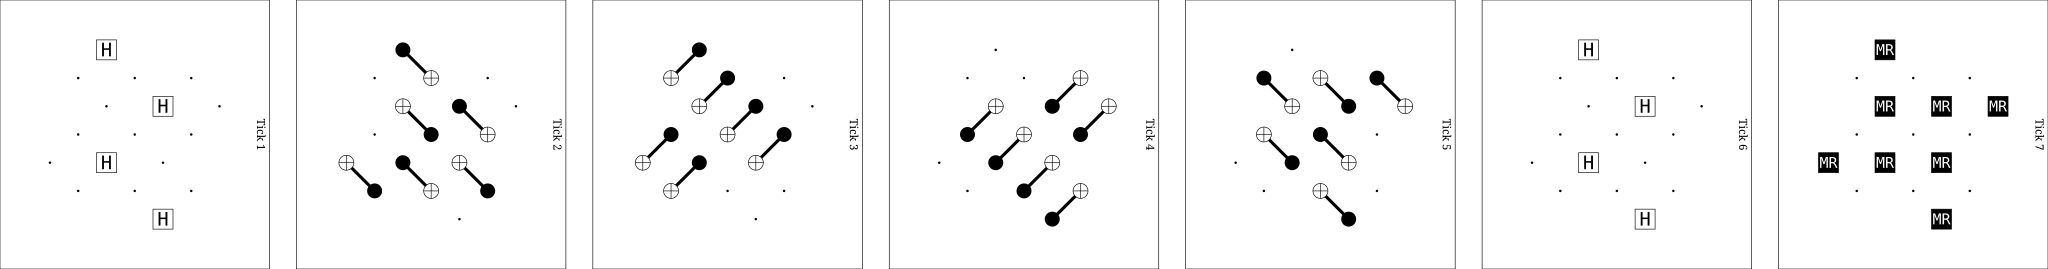

In [6]:
clean = build_circuit(CONFIG["distance"], CONFIG["rounds"], CONFIG["basis"], "none")
display(SVG(str(clean.diagram("timeslice-svg", tick=range(1, 8), rows=1))))

## A3. Where every detector sits

Stim's output is a row of bits with **no labels on the columns** (Stim result-format docs). Which bit is which stabilizer, in which round, comes only from the circuit: `circuit.get_detector_coordinates()` gives each detector's `(x, y, t)`.

`describe_detectors` turns those coordinates, plus the positions of the measurement qubits, into everything later steps need:

- `det_round[k]`, `det_slot[k]`: the round and stabilizer of detector column *k*;
- `slots`: stabilizer positions in a fixed **reading order** (top to bottom, then left to right);
- `types`, `names`: X- or Z-type, and names like X1…X4, Z1…Z4.

**How the type is found.** In a Z-basis experiment the data qubits start in 0, so only Z-type checks have a known first value and get a round-0 detector. Round-0 positions are therefore the experiment's own type; all others are the opposite type. (Mirror image for an X-basis run.) The cell checks this against the circuit itself: X-type measurement qubits are the ones that get Hadamard gates.

In [7]:
def measurement_qubit_positions(circuit):
    # (x, y) of every qubit measured before the final data-qubit readout, i.e. the measurement qubits
    meas = [inst for inst in circuit.flattened() if stim.gate_data(inst.name).produces_measurements]
    qc = circuit.get_final_qubit_coordinates()
    return {tuple(qc[t.value][:2]) for inst in meas[:-1] for t in inst.targets_copy()}

def describe_detectors(circuit, basis):
    co = circuit.get_detector_coordinates()                        # {detector: [x, y, t]}
    xyt = np.array([co[k] for k in range(circuit.num_detectors)])
    times = np.unique(xyt[:, 2])
    det_round = np.searchsorted(times, xyt[:, 2])                  # 0 .. rounds (last = final readout)
    # Stabilizer positions come from the measurement qubits, not only from detectors: with rounds = 1
    # in a Z-basis run the X checks have no detectors at all, but they still need their columns.
    positions = measurement_qubit_positions(circuit) | {(x, y) for x, y, _ in xyt}
    slots = sorted(positions, key=lambda q: (q[1], q[0]))         # reading order: top to bottom, left to right
    det_slot = np.array([slots.index((x, y)) for x, y, _ in xyt])
    first = {slots[s] for s in det_slot[det_round == 0]}           # positions with a round-0 detector
    own, other = basis.upper(), ("X" if basis.upper() == "Z" else "Z")
    types = [own if q in first else other for q in slots]
    count, names = {"X": 0, "Z": 0}, []
    for t in types:
        count[t] += 1; names.append(f"{t}{count[t]}")
    return dict(det_round=det_round, det_slot=det_slot, slots=slots, types=types, names=names,
                n_rounds=len(times), n_stab=len(slots))

info = describe_detectors(circuit, CONFIG["basis"])

# Check the inferred types against the circuit: X-type measurement qubits get Hadamards
qcoords = {tuple(v): q for q, v in circuit.get_final_qubit_coordinates().items()}
hadamard_qubits = {t.value for inst in circuit.flattened() if inst.name == "H" for t in inst.targets_copy()}
truth = ["X" if qcoords[tuple(map(float, s))] in hadamard_qubits else "Z" for s in info["slots"]]
assert truth == info["types"], "type inference disagrees with the circuit"
print("stabilizers in reading order:", " ".join(info["names"]))

ROUND_LABEL = lambda r, R: "final" if r == R - 1 else f"r{r}"
print("\ncolumn  round  stabilizer  (x, y)")
for k in range(circuit.num_detectors):
    r, s = info["det_round"][k], info["det_slot"][k]
    x, y = info["slots"][s]
    print(f"{k:6d}  {ROUND_LABEL(r, info['n_rounds']):5s}  {info['names'][s]:10s}  ({int(x)}, {int(y)})")

stabilizers in reading order: X1 Z1 X2 Z2 Z3 X3 Z4 X4

column  round  stabilizer  (x, y)
     0  r0     Z3          (0, 4)
     1  r0     Z1          (2, 2)
     2  r0     Z4          (4, 4)
     3  r0     Z2          (6, 2)
     4  r1     X1          (2, 0)
     5  r1     Z1          (2, 2)
     6  r1     X2          (4, 2)
     7  r1     Z2          (6, 2)
     8  r1     Z3          (0, 4)
     9  r1     X3          (2, 4)
    10  r1     Z4          (4, 4)
    11  r1     X4          (4, 6)
    12  r2     X1          (2, 0)
    13  r2     Z1          (2, 2)
    14  r2     X2          (4, 2)
    15  r2     Z2          (6, 2)
    16  r2     Z3          (0, 4)
    17  r2     X3          (2, 4)
    18  r2     Z4          (4, 4)
    19  r2     X4          (4, 6)
    20  final  Z3          (0, 4)
    21  final  Z1          (2, 2)
    22  final  Z4          (4, 4)
    23  final  Z2          (6, 2)


Two things to notice in that table (Notes §9):

- **Round 0 and the final row have only Z checks.** X checks measured on |0⟩ data qubits give random first results, so there is nothing to compare; and the final Z-basis readout of the data qubits can only rebuild Z parities.
- **The column order is irregular.** Rounds 1 and 2 follow the measurement order (X1 Z1 X2 Z2 Z3 X3 Z4 X4), but round 0 and the final row list Z3 Z1 Z4 Z2. Never assume the order; always map columns with the coordinates. Step 1 does this.

The drawing below is built from the circuit: data qubits are the ones read out at the end; lines are the CNOTs of one round; the dashed box marks the data qubits whose final readout forms the logical observable (the label).

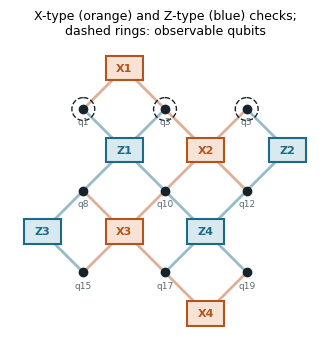

In [8]:
X_STRONG, X_SOFT = "#B4531A", "#F7E3D5"     # X-type checks
Z_STRONG, Z_SOFT = "#1C6A88", "#D8E9F0"     # Z-type checks
INK, PLAIN_SOFT = "#17232B", "#E6ECEF"      # other channels

def observable_qubits(circuit):
    # Data qubits whose final measurements make up OBSERVABLE_INCLUDE(0)
    record, qubits = [], set()
    for inst in circuit.flattened():
        if stim.gate_data(inst.name).produces_measurements:
            record += [t.value for t in inst.targets_copy()]
        elif inst.name == "OBSERVABLE_INCLUDE":
            qubits |= {record[len(record) + t.value] for t in inst.targets_copy()}
    return qubits

def draw_layout(circuit, info, ax=None):
    ax = ax or plt.subplots(figsize=(4, 4))[1]
    qc = circuit.get_final_qubit_coordinates()
    pos_to_slot = {tuple(map(float, s)): i for i, s in enumerate(info["slots"])}
    anc = {q for q, v in qc.items() if tuple(v) in pos_to_slot}
    cx = [inst for inst in circuit.flattened() if inst.name == "CX"][:4]      # first round's 4 CNOT layers
    for inst in cx:
        t = [x.value for x in inst.targets_copy()]
        for a, b in zip(t[::2], t[1::2]):
            m = a if a in anc else b
            col = X_STRONG if info["types"][pos_to_slot[tuple(qc[m])]] == "X" else Z_STRONG
            ax.plot([qc[a][0], qc[b][0]], [qc[a][1], qc[b][1]], color=col, alpha=.45, lw=2, zorder=1)
    obs = observable_qubits(circuit)
    for q, (x, y) in qc.items():
        if q in anc:
            s = pos_to_slot[(x, y)]; X = info["types"][s] == "X"
            ax.add_patch(Rectangle((x - .45, y - .3), .9, .6, fc=X_SOFT if X else Z_SOFT,
                                   ec=X_STRONG if X else Z_STRONG, lw=1.5, zorder=2))
            ax.text(x, y, info["names"][s], ha="center", va="center", fontsize=8, weight="bold",
                    color=X_STRONG if X else Z_STRONG, zorder=3)
        else:
            ax.plot(x, y, "o", color=INK, ms=6, zorder=2)
            ax.text(x, y + .38, f"q{q}", ha="center", fontsize=6.5, color="#5A6A74")
            if q in obs:
                ax.add_patch(plt.Circle((x, y), .28, fill=False, ls="--", color=INK, lw=1))
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
    ax.set_title("X-type (orange) and Z-type (blue) checks;\ndashed rings: observable qubits", fontsize=9)
    return ax

draw_layout(circuit, info); plt.show()

## A4. Sample detection events and labels

For each shot Stim draws random Pauli faults from the noise instructions, simulates the circuit, and applies the circuit's definitions:

- each `DETECTOR` XORs measurement results: **1 = this stabilizer's result changed since the previous round**;
- `OBSERVABLE_INCLUDE` XORs the final data-qubit readouts into the logical value. Because the prepared state is known, a flip of it is the **label** (Notes §5–6).

A real device gives raw measurement bits, and the same definitions are applied in software, which is why Stim output and Google's public datasets have the same form. Both ways of sampling are shown: directly, and the hardware-faithful route through raw measurements.

In [9]:
# Direct: detection events and labels in one call
dets, labels = circuit.compile_detector_sampler(seed=CONFIG["example_seed"]).sample(6, separate_observables=True)
print("detection events:", dets.shape, dets.dtype, "   labels:", labels.shape, labels.dtype)

# Hardware-faithful: raw measurement bits first, then convert exactly as an experiment would
meas = circuit.compile_sampler(seed=CONFIG["example_seed"]).sample(6)
dets_hw, labels_hw = circuit.compile_m2d_converter().convert(measurements=meas, separate_observables=True)
print("raw measurements:", meas.shape, f"= {CONFIG['rounds']} rounds x {info['n_stab']} ancillas + "
      f"{CONFIG['distance']**2} data qubits  ->  converted:", dets_hw.shape, labels_hw.shape)

detection events: (6, 24) bool    labels: (6, 1) bool
raw measurements: (6, 33) = 3 rounds x 8 ancillas + 9 data qubits  ->  converted: (6, 24) (6, 1)


In [10]:
def print_rows(dets, labels, info):
    # Print shots as Stim gives them, with the column meaning (which Stim does not give) above
    R = info["n_rounds"]
    groups = [[k for k in range(dets.shape[1]) if info["det_round"][k] == r] for r in range(R)]
    head = " | ".join(" ".join(f"{info['names'][info['det_slot'][k]]:>3s}" for k in g) for g in groups)
    rnds = " | ".join(f"{ROUND_LABEL(r, R):^{4 * len(g) - 1}s}" for r, g in enumerate(groups))
    print("        " + rnds + " || label")
    print("        " + head + " ||")
    for i, row in enumerate(dets):
        body = " | ".join(" ".join(f"{int(row[k]):>3d}" for k in g) for g in groups)
        print(f"shot {i:2d} " + body + f" ||   {int(labels[i, 0])}")

print_rows(dets, labels, info)

              r0        |               r1                |               r2                |      final      || label
         Z3  Z1  Z4  Z2 |  X1  Z1  X2  Z2  Z3  X3  Z4  X4 |  X1  Z1  X2  Z2  Z3  X3  Z4  X4 |  Z3  Z1  Z4  Z2 ||
shot  0   0   0   1   0 |   0   0   0   0   1   1   0   0 |   0   0   0   0   0   0   1   0 |   0   0   0   0 ||   0
shot  1   0   0   0   0 |   0   0   1   1   0   0   1   0 |   0   0   0   0   0   0   0   0 |   0   0   0   0 ||   0
shot  2   0   0   0   0 |   0   0   0   0   0   0   0   0 |   0   0   0   1   0   0   0   0 |   0   0   0   1 ||   0
shot  3   0   0   0   0 |   0   0   0   0   0   0   1   0 |   0   0   0   0   0   0   1   0 |   0   0   0   1 ||   1
shot  4   0   0   0   0 |   0   0   0   0   0   0   0   0 |   0   0   0   0   0   0   0   0 |   0   0   0   0 ||   0
shot  5   0   0   0   0 |   0   0   0   0   0   1   0   0 |   1   0   1   0   0   1   0   1 |   0   0   0   0 ||   0


## A5. Reading a shot

Shot 0 is the example used throughout the Notes (§11). Its events: Z4 in round 0, Z3 and X3 in round 1, Z4 in round 2; label 0.

- **A 1 means "changed since the last round"**, not "there is an error here now". An error that happens and stays changes its checks once, so they fire once and then read 0 while it persists.
- **Z4: 1, 0, 1.** Z4's answer was already flipped at its first check, stayed flipped in round 1 (no change), and flipped back in round 2.
- **Z3 and X3: 1 in round 1 only.** Both changed once and stayed changed.
- **Most likely cause** (about 6 in 10 of the matching samples in the Notes' analysis): one two-qubit gate fault on X3's measurement qubit partway through round 0. The CNOTs that follow copy its X part onto data qubits q10 and q8 (a **hook error**; Dennis et al. 2002); its other part either flips X3's own reading or leaves a phase flip on q15, so X3 fires in round 1. A later bit flip on q17 or q19 restores Z4 in round 2.
- None of the likely causes touch the readout qubits, so the right prediction is 0, and MWPM agrees (A6).

The optional cell below reproduces the cause analysis by sampling Stim's error model and recording which error mechanisms fired. Set `RUN_CAUSE_ANALYSIS = True` to run it (about a minute).

In [11]:
fired = np.flatnonzero(dets[0])
print("shot 0 fires:", ", ".join(f"{info['names'][info['det_slot'][k]]} in {ROUND_LABEL(info['det_round'][k], info['n_rounds'])}"
                                 for k in fired), "| label", int(labels[0, 0]))

RUN_CAUSE_ANALYSIS = False
if RUN_CAUSE_ANALYSIS:
    from collections import Counter
    dem_full = circuit.detector_error_model()
    errs = [inst for inst in dem_full.flattened() if inst.type == "error"]
    sampler, causes, hits = dem_full.compile_sampler(seed=1), Counter(), 0
    for _ in range(40):
        D, O, E = sampler.sample(250_000, return_errors=True)       # E: which mechanisms fired
        for h in np.flatnonzero((D == dets[0]).all(axis=1)):
            causes[tuple(np.flatnonzero(E[h]))] += 1; hits += 1
    print(f"{hits} of 10,000,000 samples match this pattern; most common causes:")
    for combo, n in causes.most_common(4):
        print(f"  {n:4d}x ", " + ".join(" ".join(str(t) for t in errs[i].targets_copy()) for i in combo))

shot 0 fires: Z4 in r0, Z3 in r1, X3 in r1, Z4 in r2 | label 0


## A6. Detector error model and the MWPM baseline

A **detector error model** (DEM) lists every independent error mechanism with its probability and the detectors and observables it flips; Stim derives it from the noisy circuit (Gidney 2021; Blume-Kohout & Young 2025; project note `DEM.md`). PyMatching builds a matching graph from it and decodes by minimum-weight perfect matching (Higgott 2021; Higgott & Gidney 2025).

MWPM outputs the same single bit the ML model will: *predicted observable flip*. A decoder fails when its prediction differs from the label. Report the **logical error rate (LER)** with its standard error, on the same test shots for every decoder.

In [12]:
dem = circuit.detector_error_model(decompose_errors=True)
matcher = pymatching.Matching.from_detector_error_model(dem)

pred0 = matcher.decode(dets[0])
pairs = matcher.decode_to_edges_array(dets[0])        # which events MWPM paired (-1 = boundary)
name = lambda k: "boundary" if k < 0 else f"{info['names'][info['det_slot'][k]]}-{ROUND_LABEL(info['det_round'][k], info['n_rounds'])}"
print("shot 0: MWPM predicts", int(pred0[0]), "| label", int(labels[0, 0]),
      "| pairs:", ", ".join(f"{name(a)}~{name(b)}" for a, b in pairs))

def mwpm_ler(circuit, dets, labels):
    m = pymatching.Matching.from_detector_error_model(circuit.detector_error_model(decompose_errors=True))
    wrong = (m.decode_batch(dets)[:, 0] != labels[:, 0])
    ler = wrong.mean()
    return ler, np.sqrt(ler * (1 - ler) / len(wrong))

D, L = circuit.compile_detector_sampler(seed=stim_seed(R0, TEST, 99)).sample(100_000, separate_observables=True)
ler, se = mwpm_ler(circuit, D, L)
print(f"MWPM LER over 100,000 shots at p={CONFIG['p']}: {ler:.3%} ± {se:.3%}   (label = 1 in {L.mean():.1%} of shots)")

shot 0: MWPM predicts 0 | label 0 | pairs: Z4-r0~Z3-r1, X3-r1~boundary, Z4-r2~boundary


MWPM LER over 100,000 shots at p=0.01: 5.725% ± 0.073%   (label = 1 in 18.4% of shots)


## A7. Save and reload a fixed dataset

> **Applies to:** validation and test sets (generate once, reuse forever). Training data can be generated on the fly instead (C4).

- **Detection events → `.b8`**: bits packed 8 per byte; the most compact dense format. It has no header, so the reader must know the bit count.
- **Labels → `.01`**: one character per shot; tiny and readable.
- **Circuit → `.stim`**: supplies the bit count *and* the meaning of every column.
- **`meta.json`**: settings, seed and Stim version.

None of Stim's six result formats carries coordinates or stabilizer types, and all load into the same 0/1 array, so the format does not affect what a model can learn (Stim result-format docs; Notes §12). The saved file, not the seed, is the reference: another Stim version would make different shots from the same seed.

In [13]:
def save_dataset(folder, circuit, dets, labels, meta):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    stim.write_shot_data_file(data=dets, path=str(folder / "dets.b8"), format="b8", num_detectors=circuit.num_detectors)
    stim.write_shot_data_file(data=labels, path=str(folder / "labels.01"), format="01", num_observables=circuit.num_observables)
    (folder / "circuit.stim").write_text(str(circuit))
    (folder / "meta.json").write_text(json.dumps({**meta, "stim_version": stim.__version__}, indent=2))

def load_dataset(folder):
    folder = Path(folder)
    c = stim.Circuit((folder / "circuit.stim").read_text())
    dets = stim.read_shot_data_file(path=str(folder / "dets.b8"), format="b8", num_detectors=c.num_detectors)
    labels = stim.read_shot_data_file(path=str(folder / "labels.01"), format="01", num_observables=c.num_observables)
    return c, dets, labels, json.loads((folder / "meta.json").read_text())

def fixed_set(role, n, circuit, folder, **meta):
    # Generate once with the role's seed, save, and from then on always reload the file
    if not (Path(folder) / "dets.b8").exists():
        d, l = circuit.compile_detector_sampler(seed=stim_seed(R0, role)).sample(n, separate_observables=True)
        save_dataset(folder, circuit, d, l, dict(role=role, shots=n, root_seed=R0, **meta))
    return load_dataset(folder)

val_c, val_d, val_l, _ = fixed_set(VAL, 20_000, circuit, OUT / "val", p=CONFIG["p"])
test_c, test_d, test_l, test_meta = fixed_set(TEST, 50_000, circuit, OUT / "test", p=CONFIG["p"])
print("test set:", test_d.shape, "| meta:", test_meta)
print("file sizes:", {f.name: f.stat().st_size for f in sorted((OUT / "test").iterdir())})

test set: (50000, 24) | meta: {'role': 2, 'shots': 50000, 'root_seed': 2026, 'p': 0.01, 'stim_version': '1.16.0'}
file sizes: {'circuit.stim': 2541, 'dets.b8': 150000, 'labels.01': 100000, 'meta.json': 95}


## A8. The pipeline as one function, and a sweep

`stim_pipeline.py` wraps A2–A7 behind a JSON config. The compact version below runs a sweep over distance, basis and SI1000-style noise and reports MWPM's LER, the label rate and the detection-event density: the baseline numbers the ML decoder has to beat (Notes §13, which used 100,000 shots per point).

Things to check in the output: LER falls as *d* grows (the code works below threshold), and the X and Z bases give similar numbers, so both need training.

In [14]:
def run_experiment(d, basis, p, shots, noise_model="si1000", role=TEST, idx=0):
    c = build_circuit(d, d, basis, noise_model, p)
    dd, ll = c.compile_detector_sampler(seed=stim_seed(R0, role, 1000 + idx)).sample(shots, separate_observables=True)
    ler, se = mwpm_ler(c, dd, ll)
    return dict(d=d, basis=basis.upper(), p=p, detectors=c.num_detectors, label_rate=ll.mean(),
                density=dd.mean(), ler=ler, se=se)

t0, rows = time.time(), []
for i, (p, basis, d) in enumerate([(p, b, d) for p in (0.001, 0.003) for b in ("z", "x") for d in (3, 5, 7)]):
    rows.append(run_experiment(d, basis, p, shots=50_000, idx=i))
print(f"{'p':>6} {'basis':>5} {'d':>2} {'detectors':>9} {'label=1':>8} {'density':>8} {'MWPM LER':>16}")
for r in rows:
    print(f"{r['p']:6.3f} {r['basis']:>5} {r['d']:2d} {r['detectors']:9d} {r['label_rate']:8.1%} {r['density']:8.2%} "
          f"{r['ler']:9.3%} ± {r['se']:.3%}")
print(f"({time.time() - t0:.0f} s)")

     p basis  d detectors  label=1  density         MWPM LER
 0.001     Z  3        24     4.4%    2.46%    0.254% ± 0.023%
 0.001     Z  5       120     9.6%    2.65%    0.062% ± 0.011%
 0.001     Z  7       336    16.4%    2.78%    0.012% ± 0.005%
 0.001     X  3        24     4.5%    2.44%    0.272% ± 0.023%
 0.001     X  5       120     9.7%    2.66%    0.050% ± 0.010%
 0.001     X  7       336    16.3%    2.77%    0.006% ± 0.003%
 0.003     Z  3        24    12.0%    6.96%    2.310% ± 0.067%
 0.003     Z  5       120    23.9%    7.60%    1.522% ± 0.055%
 0.003     Z  7       336    34.4%    7.93%    0.870% ± 0.042%
 0.003     X  3        24    12.4%    7.00%    2.372% ± 0.068%
 0.003     X  5       120    24.3%    7.60%    1.430% ± 0.053%
 0.003     X  7       336    34.5%    7.92%    0.900% ± 0.042%
(3 s)


# Part B · Preprocessing, steps 1–12

Stim gives `dets` as `bool [shots, detectors]` and `labels` as `bool [shots, 1]`. These steps turn that into model inputs.

### Which step applies to which model and which dataset

| # | Step | Priority | MLP | RNN | CNN | Transformer / GNN | Train | Validation | Test |
|---|---|---|---|---|---|---|---|---|---|
| 1 | [round, stabilizer] grid | Must | — | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 2 | mask channel | Must | — | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 3 | final-round flag | Must | — | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 4 | float32, labels kept apart | Must | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 5 | split by seed, shuffle shots | Must | ✓ | ✓ | ✓ | ✓ | split + shuffle | split | split; never altered |
| 6 | stabilizer-type channel | Should | — | ✓ | ✓ | ✓ (essential) | ✓ | ✓ | ✓ |
| 7 | 2D image per round | Should | — | — | ✓ | — | ✓ | ✓ | ✓ |
| 8 | mix of noise levels | Should | ✓ | ✓ | ✓ | ✓ | ✓ | target *p* only | target *p* only |
| 9 | basis flag | if one model sees both bases | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 10 | cumulative-XOR channel | Optional | optional | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| 11 | drop empty shots | Optional | ✓ | ✓ | ✓ | ✓ | ✓ | — | — |
| 12 | vary the number of rounds | Optional | — | ✓ | 3D fully-conv. only | ✓ if length-independent | ✓ | target lengths | target lengths |

**The rule behind the dataset columns.** Steps that define the *input format* (1–4, 6, 7, 9, 10) must be applied identically to train, validation and test, or the model sees a different kind of input at test time. Steps that shape *what the model learns from* (8, 11, 12) touch the training data only; the test set must look like real data.

A helper for drawing grids comes first. In every picture: orange = X-type check, blue = Z-type check, dark cell = 1, hatched = no detector in that slot.

In [15]:
def show_grids(panels, cell=0.34, suptitle=None):
    # panels: list of dicts with keys values (2D), and optionally mask, types (2D of 'X'/'Z'/''),
    # texts (2D strings to print instead of values), col_labels, row_labels, title,
    # kind ('events' colours by type, 'plain' uses grey/black)
    if suptitle:
        print(suptitle)
    widths = [np.asarray(p["values"]).shape[1] + 1.5 for p in panels]
    height = max(np.asarray(p["values"]).shape[0] for p in panels) + 2
    fig, axes = plt.subplots(1, len(panels), figsize=(cell * sum(widths), cell * height + .3),
                             gridspec_kw=dict(width_ratios=widths), squeeze=False)
    for ax, p in zip(axes[0], panels):
        v = np.asarray(p["values"]); R, S = v.shape
        mask = np.ones_like(v) if p.get("mask") is None else np.asarray(p["mask"])
        types = p.get("types"); kind = p.get("kind", "events")
        for r in range(R):
            for s in range(S):
                t = types[r][s] if types is not None else ""
                if not mask[r, s]:
                    ax.add_patch(Rectangle((s, r), .9, .9, fc="white", ec="#C5CFD4", hatch="////", lw=.5))
                    continue
                if kind == "events" and t in ("X", "Z"):
                    strong, soft = (X_STRONG, X_SOFT) if t == "X" else (Z_STRONG, Z_SOFT)
                else:
                    strong, soft = INK, PLAIN_SOFT
                on = v[r, s] != 0
                ax.add_patch(Rectangle((s, r), .9, .9, fc=strong if on else soft, lw=0))
                label = p["texts"][r][s] if p.get("texts") is not None else f"{v[r, s]:g}"
                ax.text(s + .45, r + .47, label, ha="center", va="center", fontsize=7 if p.get("texts") is None else 5.5,
                        color="white" if on else strong, weight="bold" if on else "normal")
        for s, lab in enumerate(p.get("col_labels", [])):
            col = X_STRONG if lab.startswith("X") else Z_STRONG if lab.startswith("Z") else "#5A6A74"
            ax.text(s + .45, -.35, lab, ha="center", va="bottom", fontsize=6.5, color=col, weight="bold")
        for r, lab in enumerate(p.get("row_labels", [])):
            ax.text(-.2, r + .47, lab, ha="right", va="center", fontsize=6.5, color="#5A6A74")
        ax.set_xlim(-1.4, S + .1); ax.set_ylim(R + .1, -1.3); ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(p.get("title", ""), fontsize=8.5, loc="left")
    plt.show()

R, S = info["n_rounds"], info["n_stab"]
ROWS = [ROUND_LABEL(r, R) for r in range(R)]
TYPES = [info["types"]] * R          # per-cell type for the [round, stabilizer] grid

## Step 1 · Reorder into a [round, stabilizer] grid

> - **Priority:** Must
> - **Models:** RNN · CNN · Transformer / GNN. *Not needed for an MLP on the flat row*, which gives every column its own weights and learns the column meanings as they are.
> - **Data:** Train · Validation · Test, identically.

**What it does.** Uses each detector's round (`det_round`) and position (`det_slot`) from A3 to place it in a `[rounds + 1, stabilizers]` table. Every row uses the same column order.

**Why.** Round-by-round models reuse the same weights on every round, so a column must mean the same stabilizer in every row. In Stim's order Z4 is the 3rd value of round 0 but the 7th of rounds 1 and 2.

*Sources:* Stim Python API (`get_detector_coordinates`); Bausch et al. 2024, §2.1 and Methods A.4.1 (one representation per stabilizer); Notes §15.

In [16]:
def to_grid(dets, info):
    # bool [N, detectors] -> uint8 [N, rounds+1, stabilizers]; slots with no detector stay 0
    grid = np.zeros((len(dets), info["n_rounds"], info["n_stab"]), np.uint8)
    grid[:, info["det_round"], info["det_slot"]] = dets
    return grid

grid = to_grid(dets, info)
assert (grid[:, info["det_round"], info["det_slot"]] == dets).all()      # nothing lost or moved
print("flat:", dets.shape, "-> grid:", grid.shape, "   (shots, rounds+1, stabilizers)")

flat: (6, 24) -> grid: (6, 4, 8)    (shots, rounds+1, stabilizers)


## Step 2 · Add a mask channel

> - **Priority:** Must
> - **Models:** RNN · CNN · Transformer / GNN (any model that uses the grid).
> - **Data:** Train · Validation · Test. The mask depends only on the circuit, so it is the same for every shot of one configuration.

**What it does.** A second grid of the same shape: 1 where a detector exists, 0 where it does not. In a Z-basis run the X checks have no detector in round 0 or in the final row.

**Why.** Empty slots are stored as 0, but 0 also means "this detector did not fire". The mask tells the model which zeros are real.

*Source:* Bausch et al. 2024, Methods A.4.1 (a learned "undefined" embedding for the off-basis stabilizers in the final round).

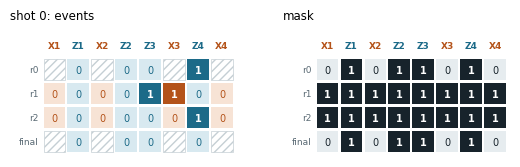

In [17]:
def make_mask(info):
    mask = np.zeros((info["n_rounds"], info["n_stab"]), np.uint8)
    mask[info["det_round"], info["det_slot"]] = 1
    return mask

mask = make_mask(info)
show_grids([dict(values=grid[0], mask=mask, types=TYPES, col_labels=info["names"], row_labels=ROWS,
                 title="shot 0: events"),
            dict(values=mask, kind="plain", col_labels=info["names"], row_labels=ROWS, title="mask")])

## Step 3 · Flag the final round

> - **Priority:** Must
> - **Models:** RNN · CNN · Transformer / GNN. *An MLP sees the final-row detectors at fixed positions and learns their role implicitly.*
> - **Data:** Train · Validation · Test.

**What it does.** A channel that is 1 on the last row and 0 elsewhere.

**Why.** The last row is not measured by the measurement qubits. It is recomputed from the final readout of the data qubits, so its errors behave differently (data-qubit readout errors instead of ancilla misreads).

*Sources:* Bausch et al. 2024, Methods A.4.1 (separate final-round embedding); Lee et al. 2026, §3.1; Baireuther et al. 2018; Varbanov et al. 2025 (final-round defects go to a separate output head).

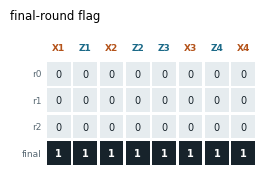

In [18]:
final_flag = np.zeros((R, S), np.uint8)
final_flag[-1, :] = 1
show_grids([dict(values=final_flag, kind="plain", col_labels=info["names"], row_labels=ROWS, title="final-round flag")])

## Step 4 · Convert to float32; keep labels separate

> - **Priority:** Must
> - **Models:** all (MLP · RNN · CNN · Transformer / GNN).
> - **Data:** Train · Validation · Test.

**What it does.** Converts Stim's `bool` arrays to `float32`, which PyTorch and TensorFlow layers expect, and keeps the labels in their own array.

**Why.** Layers need floats. Keeping labels out of the input stops the model from seeing the answer. No normalization or scaling: the values are already 0 and 1.

In [19]:
X_float = grid.astype(np.float32)          # inputs
y_float = labels.astype(np.float32)        # labels: their own array, never an input channel
print("inputs", X_float.shape, X_float.dtype, f"({X_float.nbytes} bytes)  | labels", y_float.shape, y_float.dtype)

inputs (6, 4, 8) float32 (768 bytes)  | labels (6, 1) float32


## Step 5 · Split by seed; shuffle whole shots

> - **Priority:** Must
> - **Models:** all.
> - **Data:** **Train**: own seed branch, shuffled. **Validation**: own branch, used to pick checkpoints. **Test**: own branch, saved once (A7), never filtered, rebalanced or reused for choices.

**What it does.** Draws each split from its own branch of the seed tree (A1), then shuffles the order of training shots.

**Why.** Separate random streams make the test score a measurement on shots the model never trained on. Shuffling mixes each training batch. **Only rows move**: rounds and stabilizers are positions in time and space, and moving columns would destroy their meaning.

**Independent is not the same as "patterns never seen".** At small *d* most patterns repeat: in the Notes' check at d = 3, p = 0.001, 97% of non-empty test patterns also appeared in a 200,000-shot training set. Keep those duplicates; the test set must reflect the real distribution. It does mean d = 3 says little about generalization, so report d = 5 and 7 too.

*Sources:* NumPy `SeedSequence` documentation; Senior et al. 2026, A.3.3 (reported accuracies come from a simple, separate held-out pipeline); Notes §15.

In [20]:
def sample_split(role, n, circuit, batch=0):
    return circuit.compile_detector_sampler(seed=stim_seed(R0, role, batch)).sample(n, separate_observables=True)

train_d, train_l = sample_split(TRAIN, 8_000, circuit)        # validation and test came from A7
order = np.random.default_rng(stim_seed(R0, TRAIN, 0, 999)).permutation(len(train_d))
train_d, train_l = train_d[order], train_l[order]              # rows (shots) move together with their labels

print("train", train_d.shape, "| validation", val_d.shape, "| test", test_d.shape)
print("any identical seed between splits?", len({stim_seed(R0, TRAIN, 0), stim_seed(R0, VAL), stim_seed(R0, TEST)}) < 3)

train (8000, 24) | validation (20000, 24) | test (50000, 24)
any identical seed between splits? False


## Step 6 · Add a stabilizer-type channel

> - **Priority:** Should
> - **Models:** RNN · CNN · Transformer / GNN; **essential** for Transformer / GNN and for any model trained on several distances. *An MLP gets type implicitly from fixed positions.*
> - **Data:** Train · Validation · Test. Constant per configuration.

**What it does.** A channel that is 1 in X-check columns and 0 in Z-check columns, the same in every row and every shot.

**Why.** Z checks catch X (bit-flip) errors, X checks catch Z (phase-flip) errors, and a Y error fires both. Telling the model the type lets it learn those relationships; standard MWPM decodes the X and Z parts separately and cannot use them.

*Sources:* Lange et al. 2025 (one-hot X/Z feature on every graph node; Lee et al. 2026, §3.2); Bausch et al. 2024, Methods A.4.3 (attention bias includes whether two stabilizers share a basis).

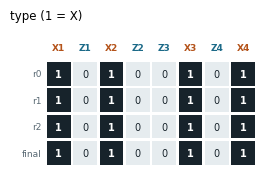

In [21]:
stab_type = np.broadcast_to(np.array([t == "X" for t in info["types"]], np.uint8), (R, S))   # 1 = X check
show_grids([dict(values=stab_type, kind="plain", col_labels=info["names"], row_labels=ROWS, title="type (1 = X)")])

## Step 7 · Lay each round out as a 2D image

> - **Priority:** Should, **CNN only**
> - **Models:** CNN. *Skip for MLP, RNN and Transformer / GNN.*
> - **Data:** Train · Validation · Test.

**What it does.** Places each stabilizer at pixel `(row, col) = (y/2, x/2)` of a `(d+1) × (d+1)` image: 4×4 for d = 3, 6×6 for d = 5. A shot becomes a short video `[rounds+1, d+1, d+1]`.

**Why.** Convolutions only look at neighbouring pixels, so stabilizers that are neighbours on the chip must be neighbouring pixels. In the step-1 column order Z1 and X3 are four columns apart although they share data qubits.

*Sources:* Bausch et al. 2024, Methods A.4.2 (stabilizers scattered onto a (d+1)×(d+1) grid before convolutions); Gicev et al. 2025 and Gu et al. 2026 (3D convolutions over the space-time volume).

image tensor: (6, 4, 4, 4)   (shots, rounds+1, d+1, d+1)
Shot 0 as one image per round (hatched = no stabilizer there, or no detector in that round):


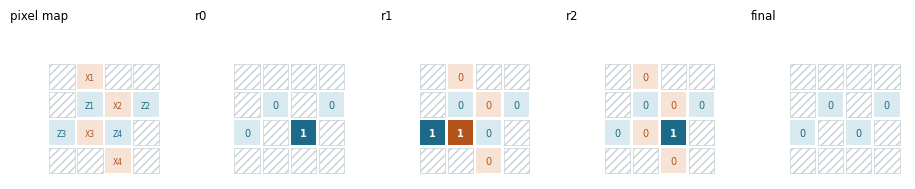

In [22]:
d = CONFIG["distance"]
pix = [(int(y) // 2, int(x) // 2) for x, y in info["slots"]]       # pixel of each stabilizer
img = np.zeros((len(grid), R, d + 1, d + 1), np.uint8)
img_mask = np.zeros((R, d + 1, d + 1), np.uint8)
img_type = [[[""] * (d + 1) for _ in range(d + 1)] for _ in range(R)]
for s, (row, col) in enumerate(pix):
    img[:, :, row, col] = grid[:, :, s]
    img_mask[:, row, col] = mask[:, s]
    for r in range(R):
        img_type[r][row][col] = info["types"][s]
print("image tensor:", img.shape, "  (shots, rounds+1, d+1, d+1)")
name_px = [[""] * (d + 1) for _ in range(d + 1)]
for s, (row, col) in enumerate(pix):
    name_px[row][col] = info["names"][s]
pixel_map = dict(values=np.zeros((d + 1, d + 1)), mask=np.array([[n != "" for n in row] for row in name_px]),
                 types=[[n[:1] for n in row] for row in name_px], texts=name_px, title="pixel map")
show_grids([pixel_map] + [dict(values=img[0, r], mask=img_mask[r], types=img_type[r], title=ROWS[r]) for r in range(R)],
           cell=0.42, suptitle="Shot 0 as one image per round (hatched = no stabilizer there, or no detector in that round):")

## Step 8 · Train on a mix of noise levels

> - **Priority:** Should
> - **Models:** all.
> - **Data:** **Train only.** Validation and test stay at the noise level you want to report.

**What it does.** Builds the training set from several noise levels and evaluates at the target level.

**Why.** The examples a model learns most from are the hard ones, where the obvious answer is wrong, and at low noise they are rare. The table counts them per 100,000 shots ("MWPM wrong"). Training at elevated noise is a form of importance sampling. Also note: plain accuracy is the wrong metric, because always predicting 0 is right on every label-0 shot; compare LER with MWPM instead.

*Sources:* Lee et al. 2026, §2.1.3; Peters 2025; Notes §19.

In [23]:
print(f"{'p':>6} {'label = 1':>10} {'MWPM wrong':>11} {'empty shots':>12}   (per 100,000 shots, d={d}, {CONFIG['basis'].upper()} basis)")
for j, p in enumerate([0.001, 0.002, 0.003, 0.005, 0.01]):
    c = build_circuit(d, CONFIG["rounds"], CONFIG["basis"], "uniform", p)
    D, L = c.compile_detector_sampler(seed=stim_seed(R0, TEST, 200 + j)).sample(100_000, separate_observables=True)
    m = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    print(f"{p:6.3f} {int(L.sum()):10,d} {int((m.decode_batch(D)[:, 0] != L[:, 0]).sum()):11,d} {int((~D.any(1)).sum()):12,d}")

# A mixed training set: equal parts per noise level, each part with its own seed, then shuffled
train_ps = [0.002, 0.003, 0.005]
parts = [build_circuit(d, CONFIG["rounds"], CONFIG["basis"], "uniform", p)
         .compile_detector_sampler(seed=stim_seed(R0, TRAIN, 1, j)).sample(3_000, separate_observables=True)
         for j, p in enumerate(train_ps)]
mix_d = np.concatenate([a for a, _ in parts]); mix_l = np.concatenate([b for _, b in parts])
perm = np.random.default_rng(stim_seed(R0, TRAIN, 1, 999)).permutation(len(mix_d))
mix_d, mix_l = mix_d[perm], mix_l[perm]
print("\nmixed training set:", mix_d.shape, "from p =", train_ps)

     p  label = 1  MWPM wrong  empty shots   (per 100,000 shots, d=3, Z basis)
 0.001      2,256          73       84,210


 0.002      4,365         326       70,918
 0.003      6,530         650       59,809
 0.005     10,428       1,711       42,611


 0.010     18,642       5,876       18,383

mixed training set: (9000, 24) from p = [0.002, 0.003, 0.005]


## Step 9 · Add a basis flag

> - **Priority:** Should, **only if one model is trained on both X- and Z-basis shots**. With one model per basis, skip it.
> - **Models:** all.
> - **Data:** Train · Validation · Test (whenever bases are mixed).

**What it does.** A channel that is all 0 for Z-basis shots and all 1 for X-basis shots (store it as one number per shot).

**Why.** The same pattern means different things in each basis: a Z-basis label tracks logical bit flips, an X-basis label tracks phase flips. The mask also differs (an X-basis run has X checks in round 0 and the final row). An alternative is a model with **two outputs**, one per basis, trained with a loss masked to the measured basis: each real shot gives only one of the two bits (Notes §6).

*Sources:* Senior et al. 2026, A.2.3 (separate readout parameters per basis); Lee et al. 2026, §2.1.2.

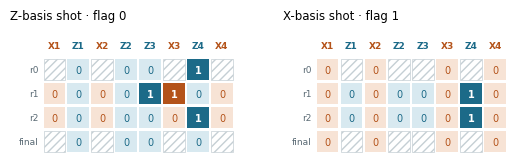

two-output labels:
 [[0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 1]] 
loss mask:
 [[1 1 1 1 0 0 0 0]
 [0 0 0 0 1 1 1 1]]


In [24]:
xc = build_circuit(d, CONFIG["rounds"], "x", "uniform", CONFIG["p"])
xinfo = describe_detectors(xc, "x")
assert xinfo["names"] == info["names"]                       # same stabilizers, same order
xd, xl = xc.compile_detector_sampler(seed=stim_seed(R0, TRAIN, 2)).sample(64, separate_observables=True)
xi = int(np.argmax([2 <= row.sum() <= 4 for row in xd]))    # pick a shot with a few events to show
x_grid, x_mask = to_grid(xd, xinfo), make_mask(xinfo)

basis_z, basis_x = np.zeros((R, S), np.uint8), np.ones((R, S), np.uint8)
show_grids([dict(values=grid[0], mask=mask, types=TYPES, col_labels=info["names"], row_labels=ROWS, title="Z-basis shot · flag 0"),
            dict(values=x_grid[xi], mask=x_mask, types=TYPES, col_labels=info["names"], row_labels=ROWS, title="X-basis shot · flag 1")])

# Two-output alternative: label matrix [N, 2] with a mask so only the measured bit is scored
basis_id = np.array([0] * 4 + [1] * 4)                      # 0 = Z-basis shot (X part), 1 = X-basis shot (Z part)
bits = np.array([0, 1, 0, 0, 1, 0, 0, 1])
y2 = np.zeros((8, 2), np.float32); m2 = np.zeros((8, 2), np.float32)
y2[np.arange(8), basis_id] = bits; m2[np.arange(8), basis_id] = 1
print("two-output labels:\n", y2.astype(int).T, "\nloss mask:\n", m2.astype(int).T)

## Step 10 · Add a cumulative-XOR channel

> - **Priority:** Optional
> - **Models:** RNN · CNN · Transformer / GNN; optional extra features for an MLP.
> - **Data:** Train · Validation · Test.

**What it does.** Runs an XOR down each column and sets empty slots to 0. For Z checks in a Z-basis run this equals the stabilizer's raw measured value; for X checks it is the value relative to the first reading. The cell checks both against Stim's raw measurements.

**Why.** Events say "changed"; the running value says "still changed". AlphaQubit trained better and more stably when given measurements as well as events, although they carry the same information.

*Source:* Bausch et al. 2024, §2.1 and Methods A.4.1.

cumulative XOR matches raw stabilizer values on 20,000 shots


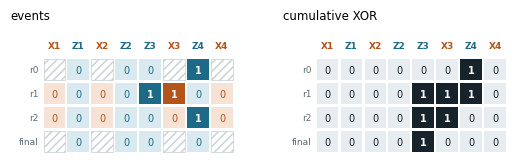

In [25]:
cumxor = np.bitwise_xor.accumulate(grid, axis=1) * mask          # [N, R, S], 0 where no detector

# Check against raw measurements (Z-basis, rounds = 3 configuration of this notebook)
if CONFIG["basis"] == "z" and CONFIG["distance"] == 3:
    m_raw = circuit.compile_sampler(seed=5).sample(20_000)
    d_raw, _ = circuit.compile_m2d_converter().convert(measurements=m_raw, separate_observables=True)
    cx = np.bitwise_xor.accumulate(to_grid(d_raw, info), axis=1)
    anc = m_raw[:, :CONFIG["rounds"] * S].reshape(-1, CONFIG["rounds"], S)   # MR order = reading order here
    for r in range(CONFIG["rounds"]):
        for s in range(S):
            expect = anc[:, r, s] if info["types"][s] == "Z" else anc[:, r, s] ^ anc[:, 0, s]
            if info["types"][s] == "Z" or r >= 1:
                assert (cx[:, r, s] == expect).all()
    print("cumulative XOR matches raw stabilizer values on 20,000 shots")

show_grids([dict(values=grid[0], mask=mask, types=TYPES, col_labels=info["names"], row_labels=ROWS, title="events"),
            dict(values=cumxor[0], kind="plain", col_labels=info["names"], row_labels=ROWS, title="cumulative XOR")])

## Step 11 · Drop empty shots from training

> - **Priority:** Optional
> - **Models:** all.
> - **Data:** **Train only.** Validation and test keep every shot, because the error rate must be measured over real data.

**What it does.** Removes shots in which no detector fired.

**Why.** An empty shot almost always has label 0, so the model learns little from it, and at low noise empty shots are most of the data (84% at d = 3, p = 0.1%).

*Sources:* Lange et al. 2025 (their code filters empty syndromes); Lee et al. 2026, §2.1.3.

In [26]:
keep = train_d.any(axis=1)
print(f"empty training shots: {(~keep).sum():,} of {len(train_d):,}; label = 1 among them: {int(train_l[~keep].sum())}")
train_d, train_l = train_d[keep], train_l[keep]
print("training set after the drop:", train_d.shape, "| test set unchanged:", test_d.shape)

empty training shots: 1,432 of 8,000; label = 1 among them: 0
training set after the drop: (6568, 24) | test set unchanged: (50000, 24)


## Step 12 · Vary the number of rounds

> - **Priority:** Optional
> - **Models:** RNN, and Transformer hybrids that handle variable length (e.g. AlphaQubit). Fully convolutional 3D CNNs can also take variable depth. *An MLP or fixed-size CNN needs one length.*
> - **Data:** **Train.** Evaluate validation and test at the lengths you care about.

**What it does.** Generates training data at several round counts; a grid has `rounds + 1` rows.

**Why.** A recurrent model reads one row at a time and can handle any length, but trained on one length it can overfit to it. AlphaQubit, trained on up to 25 cycles, held its accuracy to 100,000 cycles; AlphaQubit 2, trained on up to 168, was evaluated to one million. Shots of different lengths have different shapes, so **batch them by length**.

Note the rounds = 1 grid: in a Z-basis run with one round, the X checks never get a detector (no round-to-round comparison, no final rebuild), so their whole columns are masked. The columns stay the same because `describe_detectors` takes stabilizer positions from the measurement qubits.

*Sources:* Bausch et al. 2024, Fig. 4; Senior et al. 2026, §3.

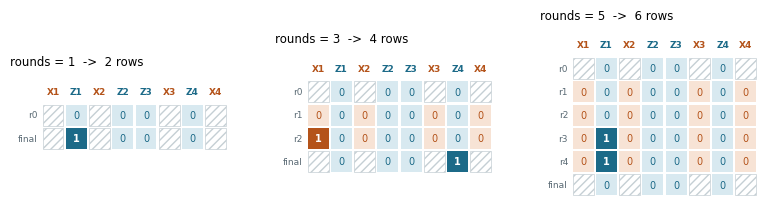

batch from rounds=1: inputs (256, 2, 8), labels (256, 1)
batch from rounds=1: inputs (256, 2, 8), labels (256, 1)
batch from rounds=5: inputs (256, 6, 8), labels (256, 1)


In [27]:
by_rounds, panels = {}, []
for k, r in enumerate((1, 3, 5)):
    c = build_circuit(d, r, CONFIG["basis"], "uniform", CONFIG["p"])
    inf = describe_detectors(c, CONFIG["basis"])
    dd, ll = c.compile_detector_sampler(seed=stim_seed(R0, TRAIN, 3, k)).sample(2_000, separate_observables=True)
    by_rounds[r] = (to_grid(dd, inf), ll)                                     # one bucket per length
    i = int(np.argmax([1 <= row.sum() <= 3 for row in dd]))
    panels.append(dict(values=by_rounds[r][0][i], mask=make_mask(inf), types=[inf["types"]] * inf["n_rounds"],
                       col_labels=inf["names"], row_labels=[ROUND_LABEL(t, inf["n_rounds"]) for t in range(inf["n_rounds"])],
                       title=f"rounds = {r}  ->  {inf['n_rounds']} rows"))
show_grids(panels)

# Batching by length: every batch comes from one bucket, so every batch has one shape
rng = np.random.default_rng(stim_seed(R0, TRAIN, 3, 999))
for _ in range(3):
    r = rng.choice(list(by_rounds)); g, l = by_rounds[r]; idx = rng.choice(len(g), 256, replace=False)
    print(f"batch from rounds={r}: inputs {g[idx].shape}, labels {l[idx].shape}")

# Part C · Putting it together

## C1. The assembled input, per model family

> - **Models:** each block below says which family it is for. **Data:** apply the same function to train, validation and test.

| Model family | Input tensor | Built from |
|---|---|---|
| **MLP** | `[N, detectors]` (+ basis flag if mixing) | Step 4 on the flat row |
| **RNN** | `[N, rounds+1, stabilizers, channels]`, read one round at a time | Steps 1–4, 6, 10 (and 9) |
| **Transformer / GNN** | same as RNN, plus normalized positions (C3) | Steps 1–4, 6, 10 (and 9) |
| **CNN** | `[N, rounds+1, channels, d+1, d+1]` | Steps 1–4, 6, 7, 10 |

Every model outputs one number per basis, the probability that the label is 1, trained with binary cross-entropy (Lee et al. 2026, §4, eqs. 18–19).

MLP               (6, 24)
RNN / Transformer (6, 4, 8, 5)   (shots, rounds+1, stabilizers, channels)
CNN               (6, 4, 5, 4, 4)   (shots, rounds+1, channels, d+1, d+1)
Shot 0, all five channels


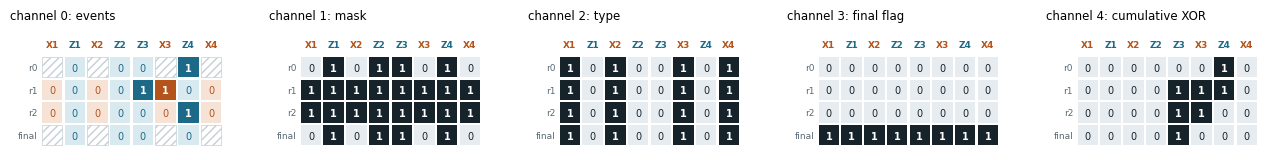

In [28]:
def preprocess(dets, info, mask, stab_type, final_flag):
    # bool [N, detectors] -> float32 [N, rounds+1, stabilizers, 5]   (RNN / Transformer / GNN)
    g = to_grid(dets, info)
    cx = np.bitwise_xor.accumulate(g, axis=1) * mask
    shape = g.shape
    return np.stack([g,                                       # channel 0: detection events (steps 1-2)
                     np.broadcast_to(mask, shape),            # channel 1: mask (step 2)
                     np.broadcast_to(stab_type, shape),       # channel 2: X/Z type (step 6)
                     np.broadcast_to(final_flag, shape),      # channel 3: final-round flag (step 3)
                     cx], axis=-1).astype(np.float32)         # channel 4: cumulative XOR (step 10)

x_seq = preprocess(dets, info, mask, stab_type, final_flag)                   # RNN / Transformer / GNN
x_mlp = dets.astype(np.float32)                                               # MLP
x_cnn = np.zeros((len(dets), R, x_seq.shape[-1], d + 1, d + 1), np.float32)   # CNN: scatter channels to pixels
for s, (row, col) in enumerate(pix):
    x_cnn[:, :, :, row, col] = x_seq[:, :, s, :]

print("MLP              ", x_mlp.shape)
print("RNN / Transformer", x_seq.shape, "  (shots, rounds+1, stabilizers, channels)")
print("CNN              ", x_cnn.shape, "  (shots, rounds+1, channels, d+1, d+1)")
show_grids([dict(values=x_seq[0, :, :, c], mask=mask if c == 0 else None, types=TYPES, kind="events" if c == 0 else "plain",
                 col_labels=info["names"], row_labels=ROWS, title=f"channel {c}: {n}")
            for c, n in enumerate(["events", "mask", "type", "final flag", "cumulative XOR"])],
           suptitle="Shot 0, all five channels")

## C2. Storing many shots: stack, don't append

> - **Data:** all splits.

- **Shots get their own axis.** The array is `X[shot, round, stabilizer, channel]`; a batch is a slice of the first axis (`X[0:256]` = 256 whole shots). Appending shots under each other in one tall table would make the model read shot 1's round 0 as round 4 of shot 0.
- **Store per shot only what changes per shot:** events (uint8) and labels, plus a basis number if mixing bases.
- **Store constants once and broadcast them** when building a batch (mask, type, final flag). NumPy's `broadcast_to` repeats them along the shot axis without copying (NumPy broadcasting docs).
- **Compute the rest per batch** (cumulative XOR, float conversion).

In [29]:
layout = np.stack([mask, stab_type, final_flag], axis=-1)      # [R, S, 3], stored once

def make_batch(events, idx):
    ev = events[idx]                                               # [B, R, S] uint8, the only per-shot input
    cx = np.bitwise_xor.accumulate(ev, axis=1) * mask              # computed on the fly
    const = np.broadcast_to(layout, ev.shape + (3,))               # a view: no copy
    return np.concatenate([ev[..., None], const, cx[..., None]], axis=-1).astype(np.float32)

events_store = to_grid(test_d, info)                               # what you would keep in memory or on disk
batch = make_batch(events_store, np.arange(256))
assert np.array_equal(batch, preprocess(test_d[:256], info, mask, stab_type, final_flag))
print("batch:", batch.shape)

# Memory for 1 million shots at d = 5, 5 rounds (120 detectors, grid 6 x 24)
N, dets5, grid5 = 1_000_000, 120, 6 * 24
print(f"b8 file           {N * ((dets5 + 7) // 8) / 1e6:8.0f} MB")
print(f"uint8 event grid  {N * grid5 / 1e6:8.0f} MB")
print(f"float32, 5 ch     {N * grid5 * 5 * 4 / 1e9:8.2f} GB   <- why batches are built on the fly")

batch: (256, 4, 8, 5)
b8 file                 15 MB
uint8 event grid       144 MB
float32, 5 ch         2.88 GB   <- why batches are built on the fly


## C3. Several code distances

> - **Models:** one model per distance (any family), or one size-independent model (Transformer / GNN, fully convolutional CNN).
> - **Data:** all splits; keep one distance per batch or pad.

A distance channel does not solve this: the problem is the **shape**. d = 3 gives `[4, 8]`, d = 5 gives `[6, 24]`. Options:

1. **One model per distance.** Simplest; start here.
2. **One model for all distances.** Needs weights that don't depend on the number of stabilizers, plus each stabilizer's position **normalized to the patch** as two extra channels, so the edges are always at −0.5 and +0.5. AlphaQubit 2 does this, with rotary position encodings and a curriculum from small to large distances.

*Sources:* Senior et al. 2026, A.1.2 and A.2.4; Lee et al. 2026, §3.2 (graph decoders share weights across distances).

d=3 grid (4, 8) | d=5 grid (6, 24)
normalized x, d=3: [-0.5  -0.17  0.17  0.5 ]
normalized x, d=5: [-0.5 -0.3 -0.1  0.1  0.3  0.5]
d=3 input padded to the d=5 shape: (6, 6, 24, 5)


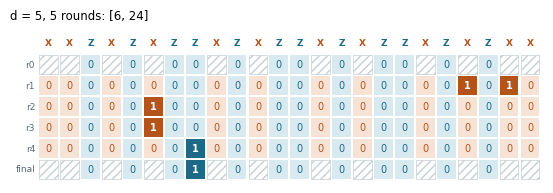

In [30]:
def positions(info, d):
    xy = np.array(info["slots"], dtype=float)                 # raw (x, y), 0 .. 2d
    return xy / (2 * d) - 0.5                                 # [stabilizers, 2], always in [-0.5, 0.5]

c5 = build_circuit(5, 5, CONFIG["basis"], "uniform", CONFIG["p"])
info5 = describe_detectors(c5, CONFIG["basis"])
d5, l5 = c5.compile_detector_sampler(seed=stim_seed(R0, TRAIN, 4)).sample(64, separate_observables=True)
print("d=3 grid", to_grid(dets, info).shape[1:], "| d=5 grid", to_grid(d5, info5).shape[1:])
print("normalized x, d=3:", np.unique(positions(info, 3)[:, 0]).round(2))
print("normalized x, d=5:", np.unique(positions(info5, 5)[:, 0]).round(2))

def pad_to(x, rounds, stabs):
    # Pad [N, R, S, C] to a larger shape; the padded cells have mask channel = 0
    out = np.zeros((x.shape[0], rounds, stabs, x.shape[-1]), x.dtype)
    out[:, :x.shape[1], :x.shape[2]] = x
    return out
print("d=3 input padded to the d=5 shape:", pad_to(x_seq, 6, 24).shape)

i5 = int(np.argmax([3 <= row.sum() <= 6 for row in d5]))
show_grids([dict(values=to_grid(d5, info5)[i5], mask=make_mask(info5), types=[info5["types"]] * info5["n_rounds"],
                 col_labels=[t for t in info5["types"]], row_labels=[ROUND_LABEL(t, 6) for t in range(6)],
                 title="d = 5, 5 rounds: [6, 24]")], cell=0.27)

## C4. Streaming batches into PyTorch

> - **Models:** any PyTorch model. **Data:** Train (endless stream). Validation and test come from the saved files of A7.

Stim makes data far faster than a model can learn from it (about 1.6 million d = 5 shots per second on two CPU cores in our test), so training batches can be generated on demand and memory holds one batch at a time. Each batch gets its own seed from the tree, so batch *k* is always the same and a stopped run can resume exactly. With several DataLoader workers, worker *w* makes batches *w*, *w + n*, …, so workers never duplicate data.

`train_streaming.py` adds the training loop, validation, checkpoints and resume.

*Sources:* PyTorch `torch.utils.data` documentation (IterableDataset and workers); Bausch et al. 2024, §2.2 (pretraining on simulated data, then fine-tuning on device data).

In [31]:
try:
    import torch
    from torch.utils.data import IterableDataset, DataLoader
except ImportError:
    torch = None
    print("PyTorch not installed: skipping C4 (pip install torch)")

if torch is not None:
    class StimStream(IterableDataset):
        # Endless training batches; batch k mixes equal parts of every training noise level
        def __init__(self, ps, batch_size, start_batch=0):
            self.ps, self.bs, self.start = ps, batch_size, start_batch

        def __iter__(self):
            wi = torch.utils.data.get_worker_info()
            wid, nw = (wi.id, wi.num_workers) if wi else (0, 1)
            circuits = [build_circuit(CONFIG["distance"], CONFIG["rounds"], CONFIG["basis"], "uniform", p) for p in self.ps]
            part, k = self.bs // len(circuits), self.start + wid
            while True:
                dd, ll = zip(*[c.compile_detector_sampler(seed=stim_seed(R0, TRAIN, 10_000 + k, j)).sample(part, separate_observables=True)
                               for j, c in enumerate(circuits)])
                dd, ll = np.concatenate(dd), np.concatenate(ll)
                perm = np.random.default_rng(stim_seed(R0, TRAIN, 10_000 + k, 999)).permutation(len(dd))
                x = preprocess(dd[perm], info, mask, stab_type, final_flag)
                yield torch.from_numpy(x), torch.from_numpy(ll[perm].astype(np.float32))
                k += nw

    loader = DataLoader(StimStream([0.002, 0.003, 0.005], batch_size=768), batch_size=None)
    for step, (xb, yb) in enumerate(loader):
        print(f"batch {step}: inputs {tuple(xb.shape)} {xb.dtype}, labels {tuple(yb.shape)}, label rate {yb.mean():.3f}")
        if step == 2:
            break

batch 0: inputs (768, 4, 8, 5) torch.float32, labels (768, 1), label rate 0.068
batch 1: inputs (768, 4, 8, 5) torch.float32, labels (768, 1), label rate 0.078
batch 2: inputs (768, 4, 8, 5) torch.float32, labels (768, 1), label rate 0.055


# Checklist before training

- [ ] Each split comes from its own seed branch; validation and test are **saved files**, generated once (A1, A7, Step 5).
- [ ] Columns are mapped with detector coordinates, not assumed (A3, Step 1).
- [ ] The input-format steps (1–4, 6, 7, 9, 10) are the **same function** for train, validation and test (C1).
- [ ] Steps 8, 11, 12 touch **training data only**.
- [ ] The test set is never filtered, rebalanced or used to choose settings.
- [ ] The score is **logical error rate vs MWPM on the same test shots**, with error bars, for each basis and distance (A6, A8).

# References

- **Gidney 2021.** C. Gidney, *Stim: a fast stabilizer circuit simulator*, Quantum 5, 497 (2021). [arXiv:2103.02202](https://arxiv.org/abs/2103.02202)
- **Stim docs.** [Result formats](https://github.com/quantumlib/Stim/blob/main/doc/result_formats.md); [Python API reference](https://github.com/quantumlib/Stim/blob/main/doc/python_api_reference_vDev.md)
- **Higgott 2021.** O. Higgott, *PyMatching*, [arXiv:2105.13082](https://arxiv.org/abs/2105.13082); **Higgott & Gidney 2025**, *Sparse blossom*, Quantum 9, 1600. [arXiv:2303.15933](https://arxiv.org/abs/2303.15933)
- **Gidney, Newman, McEwen 2022.** *Benchmarking the planar honeycomb code*, Quantum 6, 813 (Table 3: SI1000). [arXiv:2202.11845](https://arxiv.org/abs/2202.11845)
- **Bausch et al. 2024.** *Learning high-accuracy error decoding for quantum processors* (AlphaQubit), Nature 635, 834. [doi:10.1038/s41586-024-08148-8](https://doi.org/10.1038/s41586-024-08148-8)
- **Senior et al. 2026.** *A scalable and real-time neural decoder for topological quantum codes* (AlphaQubit 2). [arXiv:2512.07737](https://arxiv.org/abs/2512.07737)
- **Lee et al. 2026.** C. Lee, T. Hur, J. Jae, D. K. Park, *Machine Learning Approaches to Decoding Topological Quantum Codes*. [arXiv:2608.15760](https://arxiv.org/abs/2608.15760)
- **Lange et al. 2025.** *Data-driven decoding of quantum error correcting codes using graph neural networks*, Phys. Rev. Research 7, 023181. [arXiv:2307.01241](https://arxiv.org/abs/2307.01241); code: [LangeMoritz/GNN_decoder](https://github.com/LangeMoritz/GNN_decoder)
- **Varbanov et al. 2025.** *Neural network decoder for near-term surface-code experiments*, Phys. Rev. Research 7, 013029. [arXiv:2307.03280](https://arxiv.org/abs/2307.03280)
- **Baireuther et al. 2018.** *Machine-learning-assisted correction of correlated qubit errors in a topological code*, Quantum 2, 48.
- **Gicev et al. 2025.** *Fully convolutional 3D neural network decoders for surface codes with syndrome circuit noise*. [arXiv:2506.16113](https://arxiv.org/abs/2506.16113)
- **Gu et al. 2026.** *Scalable neural decoders for practical fault-tolerant quantum computation*. [arXiv:2604.08358](https://arxiv.org/abs/2604.08358)
- **Peters 2025.** *Importance sampling for data-driven decoding of quantum error-correcting codes*. [arXiv:2505.22741](https://arxiv.org/abs/2505.22741)
- **Dennis et al. 2002.** *Topological quantum memory*, J. Math. Phys. 43, 4452 (hook errors). [arXiv:quant-ph/0110143](https://arxiv.org/abs/quant-ph/0110143)
- **Blume-Kohout & Young 2025.** *Estimating detector error models from syndrome data*. [arXiv:2504.14643](https://arxiv.org/abs/2504.14643)
- **Fowler et al. 2012.** *Surface codes: Towards practical large-scale quantum computation*, Phys. Rev. A 86, 032324. [arXiv:1208.0928](https://arxiv.org/abs/1208.0928)
- **Library docs.** [NumPy SeedSequence](https://numpy.org/doc/stable/reference/random/parallel.html) · [NumPy broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) · [PyTorch data loading](https://pytorch.org/docs/stable/data.html)
- **Notes.** *QEC Decoder Data Notes* (team reference PDF), section numbers as cited.